In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.preprocessing import StandardScaler
import json
import pandas as pd


In [34]:
file_path = '../data/2_cleaned_data.csv'
data = pd.read_csv(file_path, sep=',')
data.info()

with open("../config.json") as f:
    cfg = json.load(f)

rc_target = cfg['rc']
rf_target = cfg['rf']
target = cfg["target"]
file_name = cfg["file_name"]
random_state = cfg["split"]["random_state"]
print(rf_target)

<class 'pandas.DataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   chanvre 5                                    1216 non-null   float64
 1   chanvre 15                                   1216 non-null   float64
 2   bambou 5                                     1216 non-null   float64
 3   bambou 15                                    1216 non-null   float64
 4   lin 5                                        1216 non-null   float64
 5   lin 6                                        1216 non-null   float64
 6   lin 15                                       1216 non-null   float64
 7   miscanthus 5                                 1216 non-null   float64
 8   miscanthus 15                                1216 non-null   float64
 9   Days                                         1216 non-null   int64  
 10  Slump (mm) 

# 3. Statistical Analysis (EDA)

## 3.1 Distribution of the target variable

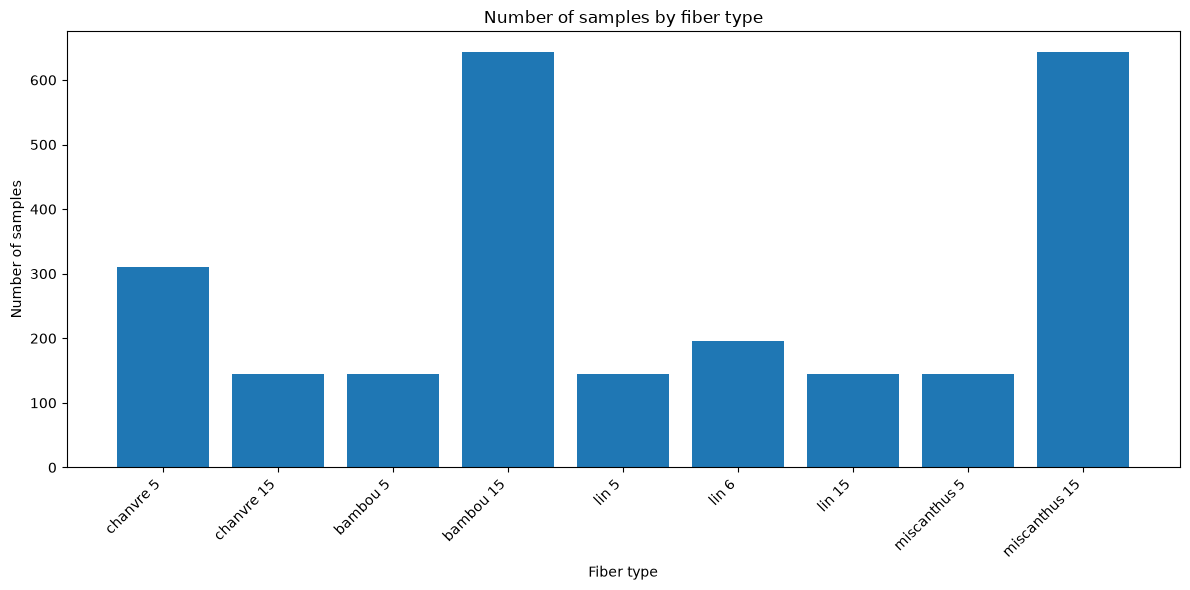

In [35]:
fiber_cols = ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 
              'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15']

counts = {fiber: data[fiber].sum() for fiber in fiber_cols}

plt.figure(figsize=(12, 6))
plt.bar(counts.keys(), counts.values())
plt.xlabel('Fiber type')
plt.ylabel('Number of samples')
plt.title('Number of samples by fiber type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Distribution of CS (Mpa)')

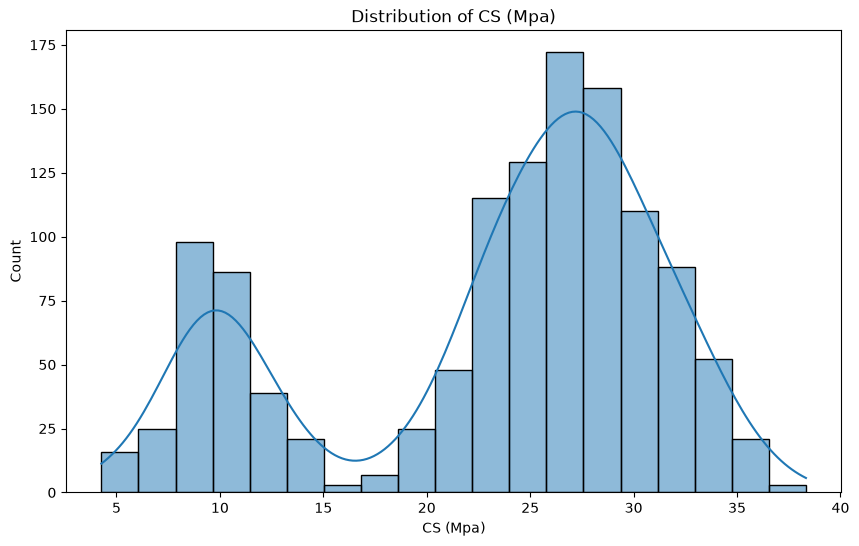

In [36]:
#Distribution of the target variable
plt.figure(figsize=(10, 6))
sns.histplot(data[target], kde=True)
plt.title(f'Distribution of {target}')

Text(0.5, 1.0, 'Distribution of Days')

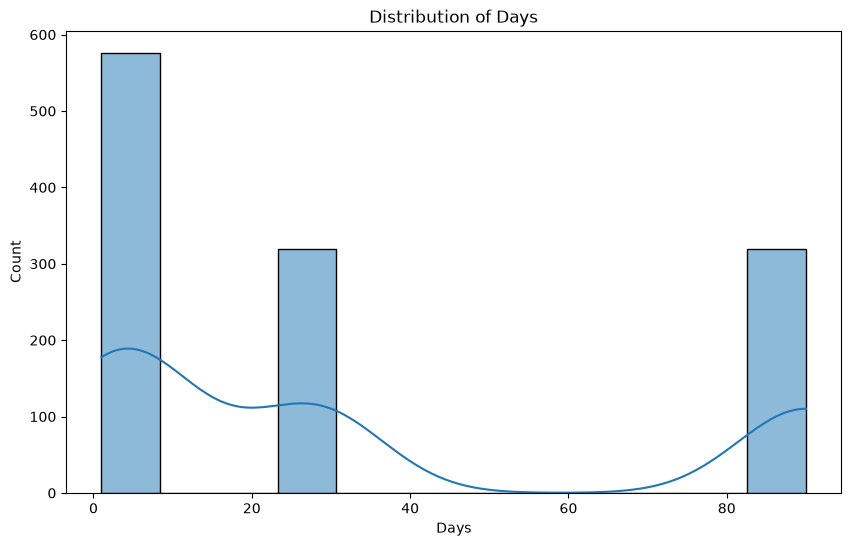

In [37]:
#Distribution of curring time : 
plt.figure(figsize=(10, 6))
sns.histplot(data['Days'], kde=True)
plt.title(f'Distribution of Days')

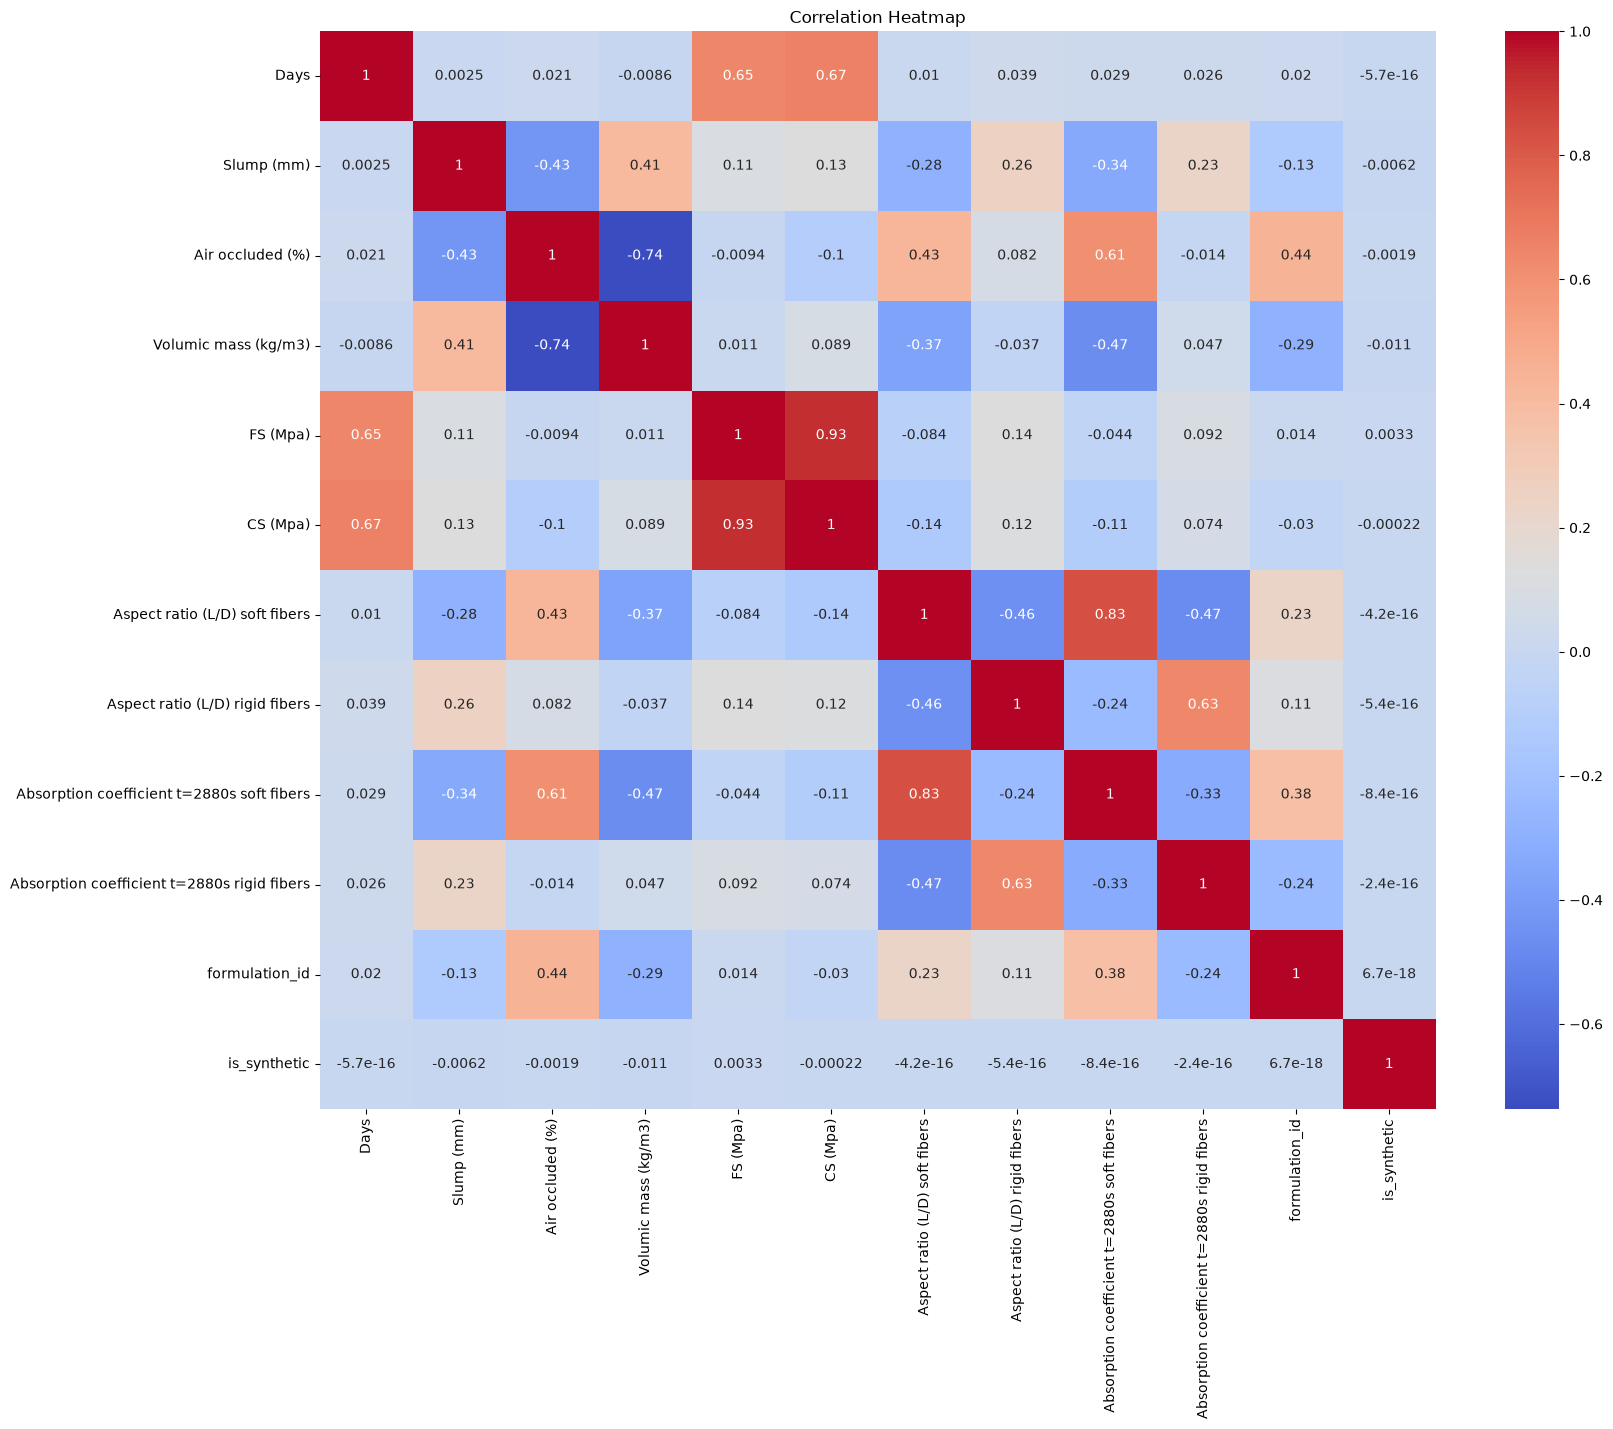

In [38]:
fiber_cols = ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 
              'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15',
              'ch.antif.', 'ch.strux']

numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
numerical_columns = [col for col in numerical_columns if col not in fiber_cols]
# Correlation heatmap for numerical features
plt.figure(figsize=(18, 14))
sns.heatmap(data[numerical_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## 3.2 Distribution of the Target Variable Across Discrete Numerical Features

Days has 4 distinct values, distribution by CS (Mpa):


<Figure size 1000x400 with 0 Axes>

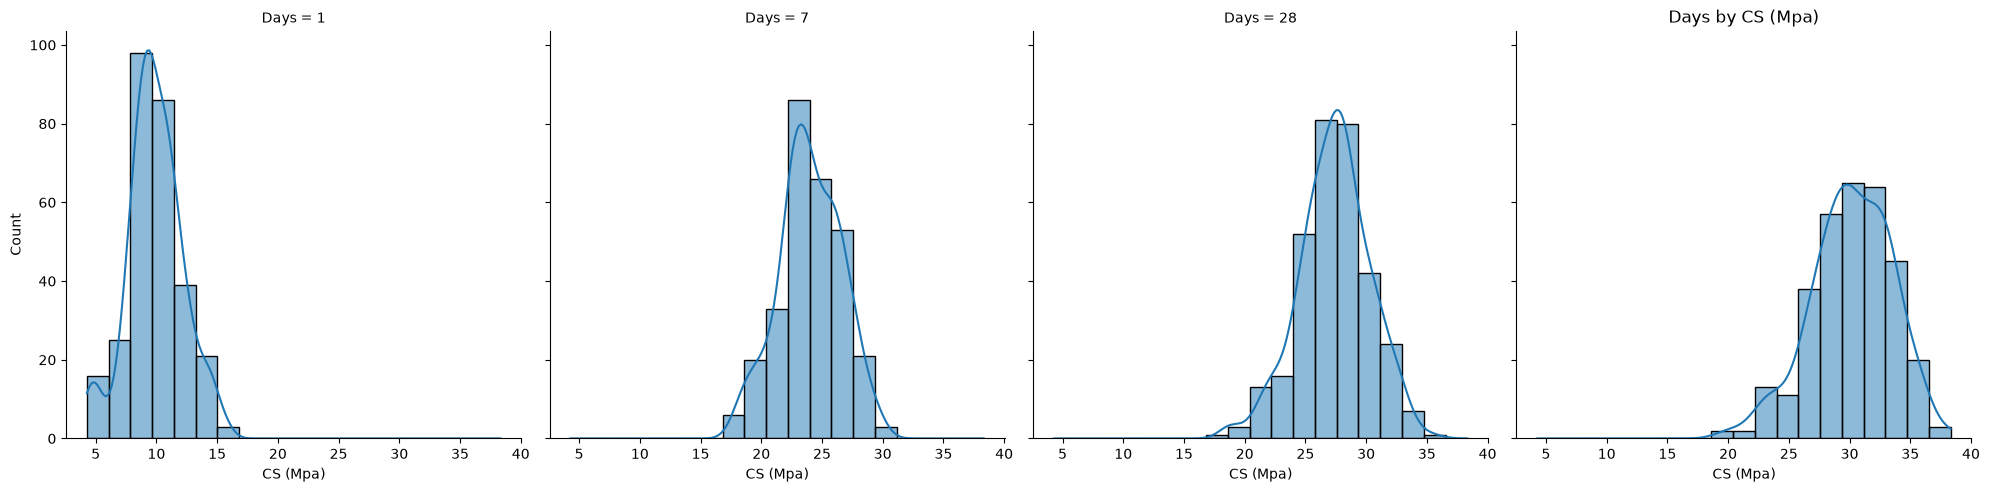

Aspect ratio (L/D) soft fibers has 5 distinct values, distribution by CS (Mpa):


<Figure size 1000x400 with 0 Axes>

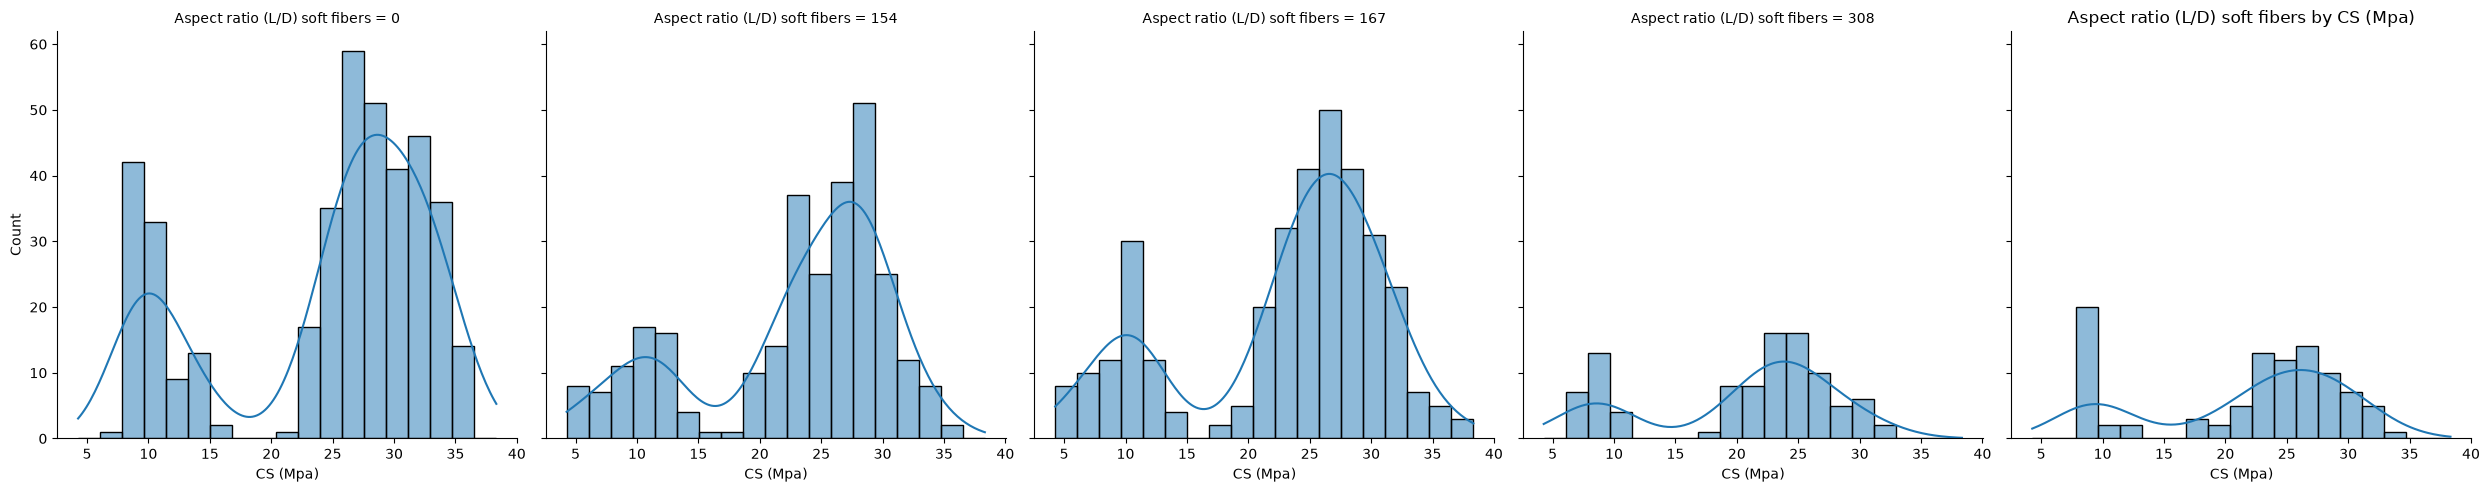

Aspect ratio (L/D) rigid fibers has 5 distinct values, distribution by CS (Mpa):


<Figure size 1000x400 with 0 Axes>

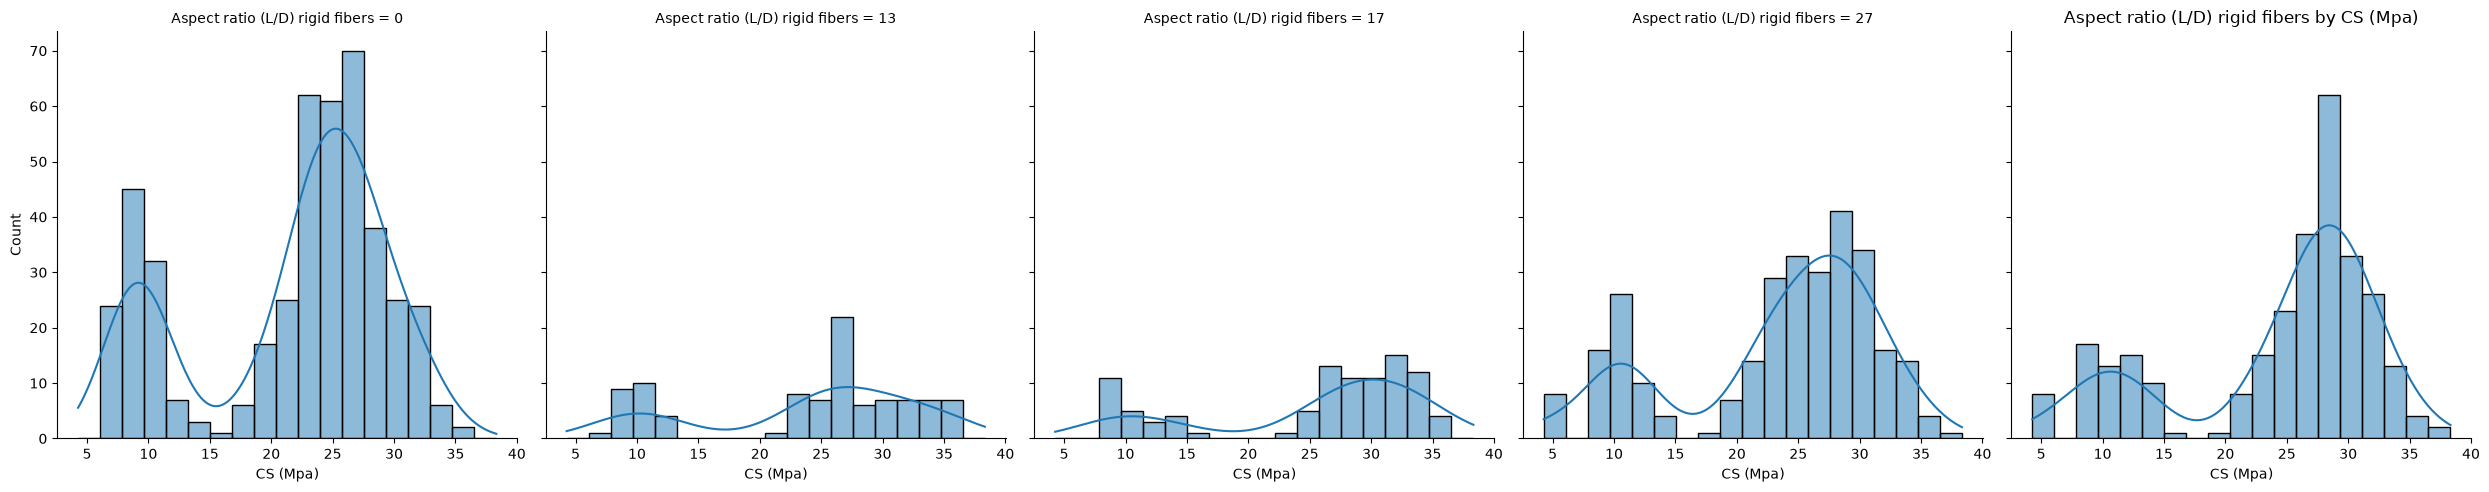

Absorption coefficient t=2880s soft fibers has 5 distinct values, distribution by CS (Mpa):


<Figure size 1000x400 with 0 Axes>

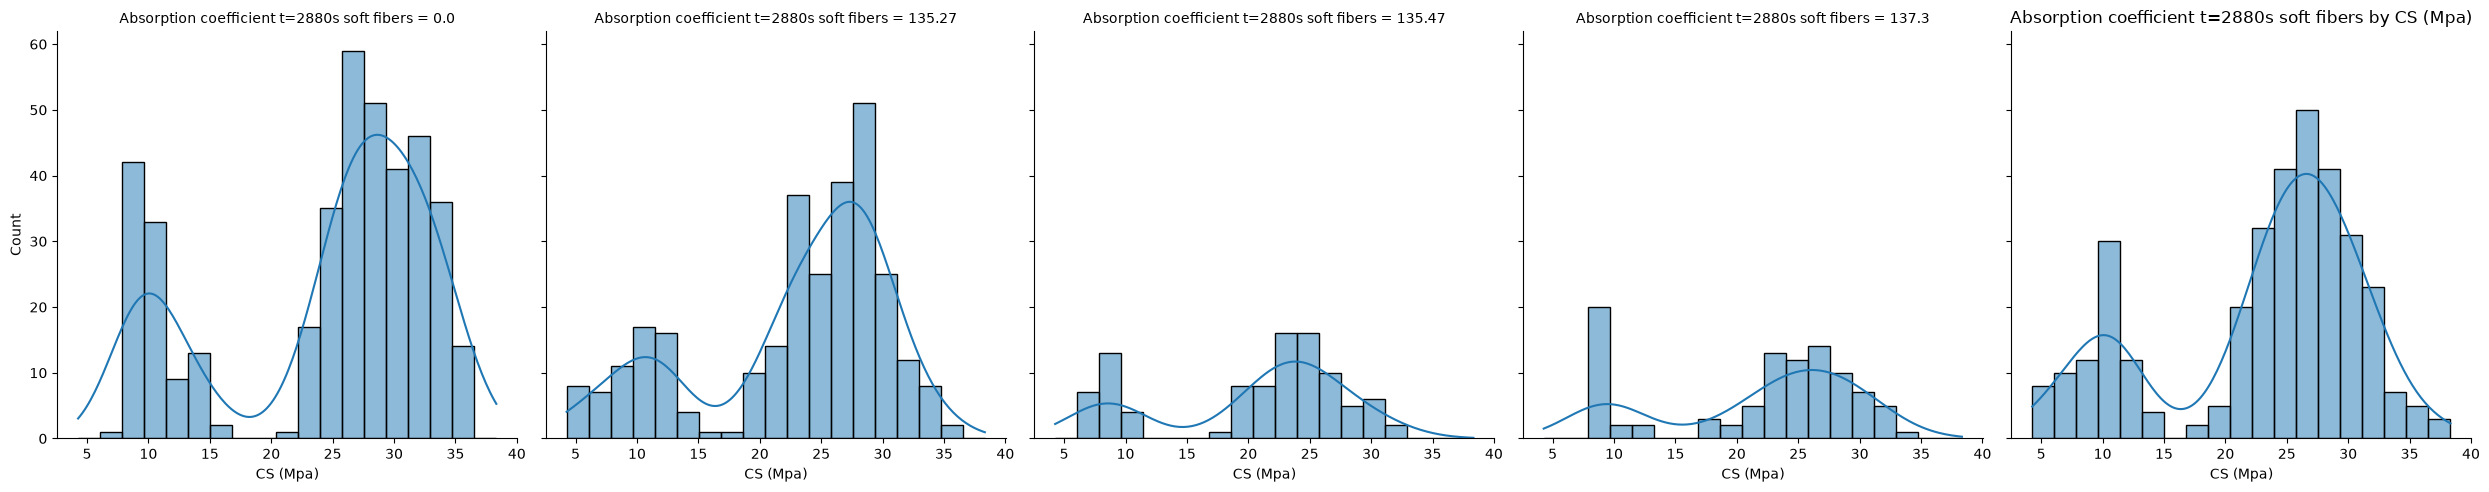

Absorption coefficient t=2880s rigid fibers has 5 distinct values, distribution by CS (Mpa):


<Figure size 1000x400 with 0 Axes>

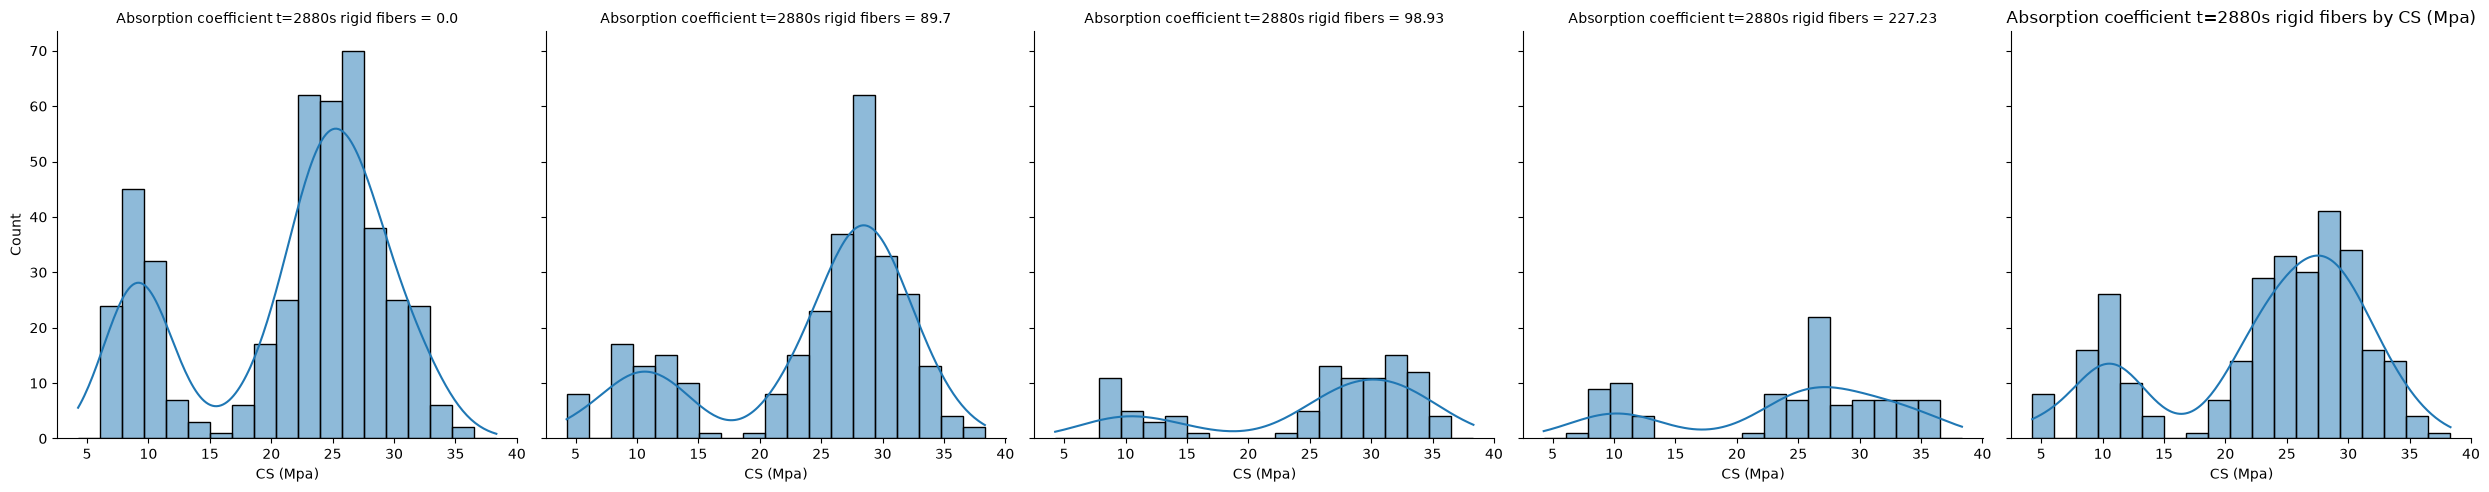

is_synthetic has 2 distinct values, distribution by CS (Mpa):


<Figure size 1000x400 with 0 Axes>

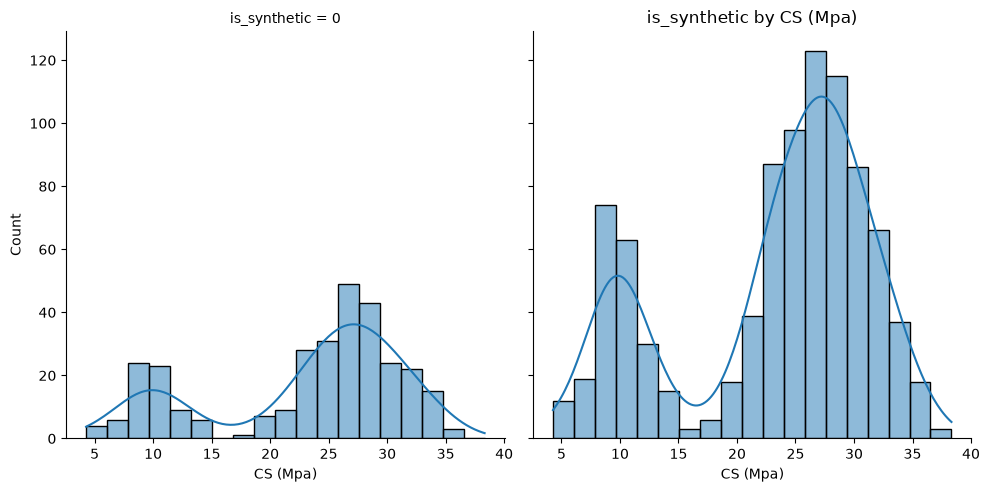

In [39]:
numerical_columns_with_min_distinct_values = [col for col in numerical_columns if data[col].nunique() < 15]
for column in numerical_columns_with_min_distinct_values:
    print(f'{column} has {data[column].nunique()} distinct values, distribution by {target}:')
    plt.figure(figsize=(10, 4))
    sns.displot(data=data, x=target, col=column, kde=True)
    plt.title(f'{column} by {target}')
    plt.show()

## 3.3 Linear / Non-linear Relationships

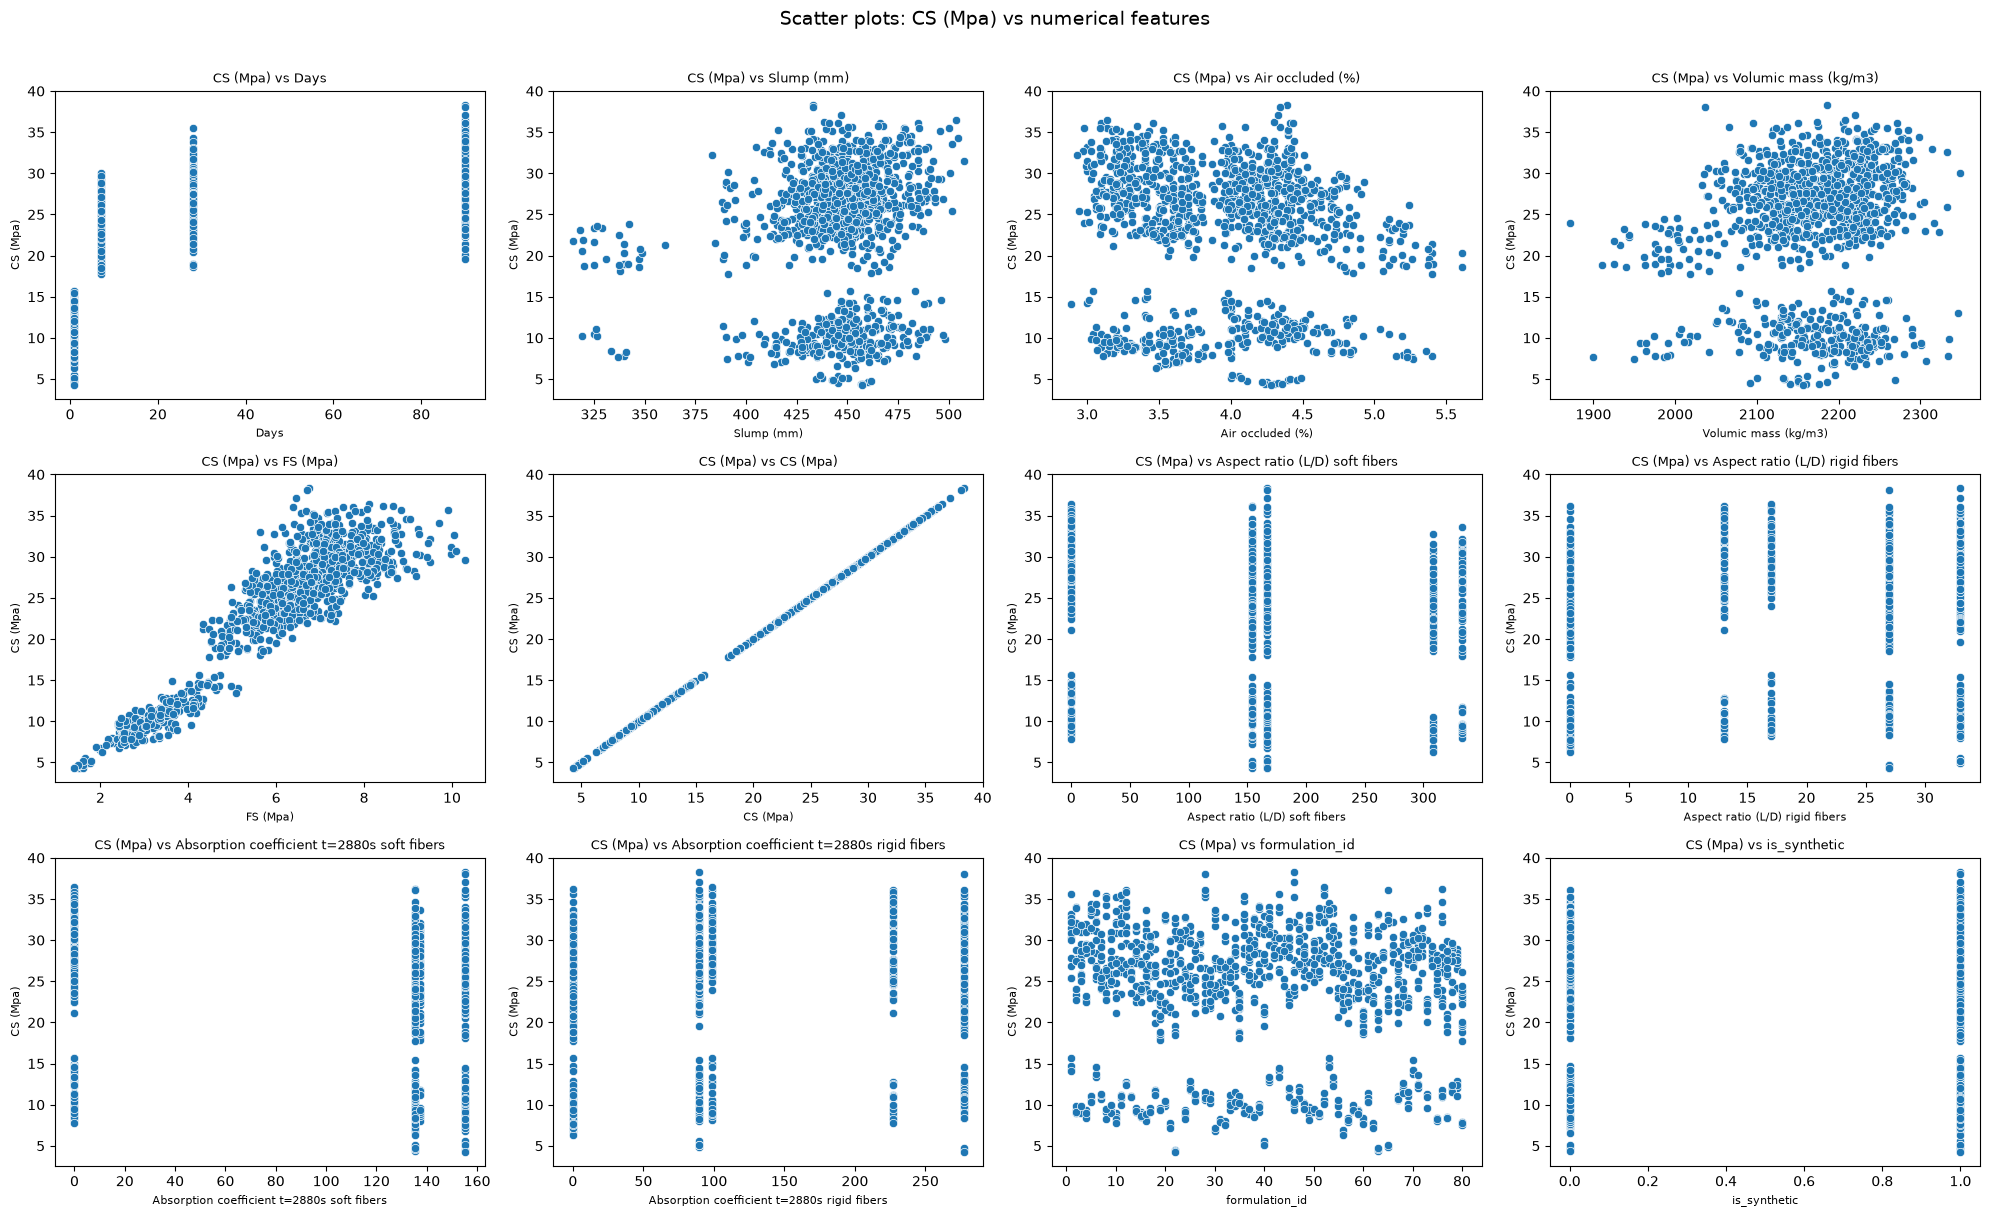

In [40]:
cols_to_plot = [col for col in numerical_columns if col not in ['is_temoin'] and 'MEB' not in col]

n_cols = 4
n_rows = -(-len(cols_to_plot) // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(cols_to_plot):
    sns.scatterplot(x=data[column], y=data[target], ax=axes[i])
    axes[i].set_title(f'{target} vs {column}', fontsize=9)
    axes[i].set_xlabel(column, fontsize=8)
    axes[i].set_ylabel(target, fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Scatter plots: {target} vs numerical features', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


## 4. Feature Selection and Consistency

<p style="color: grey;">
The column <strong>Rf (MPa) or Rc (Mpa)</strong> depending on the target value is removed to prevent data leakage. Flexural strength and compressive strength are measured simultaneously during the same mechanical test, making them strongly correlated features (r = 0.9388). Keeping Rf as a predictor would give the model information that is unavailable at inference time in a real-world scenario, rendering the prediction of Rc practically meaningless.
</p>

In [41]:
if(target == rc_target):
    print(data[rf_target].corr(data[rc_target]))
    data.drop(rf_target, axis=1, inplace=True)
else: 
    print(data[rc_target].corr(data[rc_target]))
    data.drop(rc_target, axis=1, inplace=True)

0.9262566030072615


C:\Users\matte\AppData\Local\Temp\ipykernel_3520\3564682922.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(rf_target, axis=1, inplace=True)


## 6. CSV Export

In [42]:
# export to csv
data.to_csv(f"../data/{file_name}.csv", index=False)